# Cadena completa con lazo de Nb: filtro ambiente + filtro criogénico

**Qué se va a medir.** El filtro criogénico no se puede medir solo: su salida
termina en el portamuestras y no hay cable que vuelva afuera. Por eso se unen en el
portamuestras dos canales con una pieza de Nb (+ con +, − con −). La señal baja por
el canal A y sube por el canal B, y generador y analizador quedan afuera. Entre + y −,
donde iría la juntura, puede ir una carga $R_L$.

Lo que mide el analizador es **toda la cadena**:

```
generador ─► ambiente A ─► criogénico A ─► Nb + R_L ─► criogénico B ─► ambiente B ─► analizador
 (1 V, 50 Ω)  (afuera)      (adentro)      (portamuestras)  (adentro)    (afuera)      (50 Ω)
```

Por eso hay que simular la cadena entera, no solo el criogénico.

**Los dos filtros son distintos en algo importante:**
- *Ambiente*: cada línea (+ y −) tiene su propio filtro R–C–R–C, con los **C a tierra**.
- *Criogénico*: los **C van entre + y −**. Solo filtra lo que es *diferencia* entre
  las líneas (modo diferencial).

Plan del notebook:
1. Parámetros y modelo (análisis nodal).
2. Validación contra valores conocidos.
3. Ambiente solo, como ya lo midieron, con lugar para cargar sus valores.
4. Cadena completa: curvas, $f_c$ vs $R_L$, aporte del criogénico, tabla por configuración.

## 1. Librerías

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd
from scipy.optimize import brentq

## 2. Parámetros (editables)
- `AMB_A` y `AMB_B`: qué configuración del filtro ambiente tiene cada canal.
  Pueden ser distintas.
- `L_nb`, `d_nb`: geometría del alambre de Nb.
- `PISO_RUIDO_dB`: piso de ruido del analizador, para el gráfico 4.

In [2]:
# --- Filtro ambiente: las 6 configuraciones (R por resistencia, C por capacitor) ---
CONFIGS_AMB = {
    "150 Ω / 2,2 µF": (150.0, 2.2e-6),
    "150 Ω / 1 µF":   (150.0, 1.0e-6),
    "51 Ω / 2,2 µF":  (51.0,  2.2e-6),
    "51 Ω / 1 µF":    (51.0,  1.0e-6),
    "15 Ω / 2,2 µF":  (15.0,  2.2e-6),
    "15 Ω / 1 µF":    (15.0,  1.0e-6),
}
AMB_A = "15 Ω / 1 µF"     # configuración del canal A (por donde entra el generador)
AMB_B = "15 Ω / 1 µF"     # configuración del canal B (por donde sale al analizador)

# --- Filtro criogénico (igual en todos los canales) ---
R_cry = 22.0      # Ω, cada una de las 3 resistencias en serie por línea
C_cry = 47e-9     # F, cada uno de los 2 capacitores entre + y −

# --- Instrumentos ---
V_gen = 1.0       # V
R_gen = 50.0      # Ω, resistencia interna del generador
R_an = 50.0       # Ω, impedancia de entrada del analizador

# --- Alambre de Nb ---
rho_nb = 15e-8    # Ω·m (= 15 µΩ·cm, a temperatura ambiente)
L_nb = 2e-2       # m
d_nb = 50e-6      # m

# --- Barrido y gráficos ---
f = np.logspace(-1, 6, 701)     # 0,1 Hz a 1 MHz, 100 puntos por década
F_BAJA = 0.1                    # Hz: frecuencia de referencia para el nivel "de continua"
PISO_RUIDO_dB = -90.0           # dB, piso de ruido del analizador (gráfico 4)

ABIERTO = np.inf                # para pedir R_L abierta (sin carga)

## 3. Resistencia del Nb
En frío es superconductor ($R_{nb} = 0$). En caliente, $R_{nb} = \rho L/(\pi d^2/4)$.

In [3]:
R_nb_caliente = rho_nb * L_nb / (np.pi * d_nb**2 / 4)
R_nb_frio = 0.0
print(f"R_nb en caliente = {R_nb_caliente:.3f} Ω por alambre")

R_nb en caliente = 1.528 Ω por alambre


## 4. El modelo: análisis nodal

Es el mismo método que en `lazo_nb_carga.ipynb`, pero escrito de forma general para
poder armar circuitos distintos con las mismas piezas.

**Kirchhoff en forma matricial.** Cada nodo tiene un voltaje desconocido. En cada
nodo, la suma de las corrientes que salen es cero. Con admitancias $Y = 1/Z$ queda
$\mathbf{Y}\mathbf{V} = \mathbf{I}$. Un componente $y$ entre los nodos $a$ y $b$ suma
$+y$ en $Y_{aa}$ y $Y_{bb}$, y $-y$ en $Y_{ab}$ y $Y_{ba}$.

**Tierra.** Ahora sí hay tierra (los C del filtro ambiente van a tierra), y se usa como
nodo de referencia ($V = 0$). Su fila y columna se sacan del sistema.

**Cables (resistencia cero).** Un cable no se puede poner como componente porque
tendría admitancia infinita. Lo que hace un cable es convertir dos puntos en **el
mismo nodo**. La función lleva una lista de "alias": si A− está unido a tierra, cada
vez que aparece "A−" se usa "GND". Así se resuelven:
- el Nb superconductor,
- $R_L = 0$ (corto),
- la opción "sin crio" (el criogénico se reemplaza por cables),
- la malla de los instrumentos a tierra.

**Fuente.** El generador (V con $R_{gen}$ en serie) entra como su equivalente Norton:
una corriente $V/R_{gen}$ en paralelo con $R_{gen}$.

In [4]:
def resolver(frec, componentes, cables, fuente, salida):
    '''Resuelve el circuito a una frecuencia y devuelve el voltaje de salida (complejo).

    componentes: lista de (nodo_a, nodo_b, Z), con Z un número o una función de w
                 (para los capacitores). Z = inf se ignora (circuito abierto).
    cables:      lista de (nodo_a, nodo_b) unidos sin resistencia (= mismo nodo).
    fuente:      (nodo_+, nodo_-, V, R_serie) -> generador de Thévenin.
    salida:      (nodo_+, nodo_-) entre los que se mide el voltaje.
    '''
    w = 2 * np.pi * frec

    # --- Unir los nodos conectados por cables ---
    # 'jefe' dice a qué nodo representativo pertenece cada nombre.
    jefe = {}
    def representante(nodo):
        jefe.setdefault(nodo, nodo)
        while jefe[nodo] != nodo:
            nodo = jefe[nodo]
        return nodo
    for a, b in cables:
        ra, rb = representante(a), representante(b)
        if ra != rb:
            if rb == "GND":          # si uno de los dos es tierra, que mande tierra
                ra, rb = rb, ra
            jefe[rb] = ra

    # --- Numerar los nodos (tierra es el 0) ---
    numero = {}
    def indice(nodo):
        r = representante(nodo)
        if r not in numero:
            numero[r] = len(numero)
        return numero[r]
    indice("GND")

    # --- Lista de admitancias ---
    admitancias = []
    for a, b, Z in componentes:
        z = Z(w) if callable(Z) else Z
        if np.isinf(z):
            continue                              # abierto: no conecta nada
        admitancias.append((indice(a), indice(b), 1 / z))
    f_mas, f_menos, V, R_serie = fuente
    admitancias.append((indice(f_mas), indice(f_menos), 1 / R_serie))   # R interna (Norton)

    # --- Matriz de admitancias y vector de corrientes ---
    N = len(numero)
    Y = np.zeros((N, N), dtype=complex)
    for i, j, y in admitancias:
        if i == j:
            continue                              # componente en corto: no aporta
        Y[i, i] += y
        Y[j, j] += y
        Y[i, j] -= y
        Y[j, i] -= y
    I = np.zeros(N, dtype=complex)
    I[indice(f_mas)] += V / R_serie
    I[indice(f_menos)] -= V / R_serie

    # --- Resolver con tierra (nodo 0) como referencia ---
    resto = list(range(1, N))
    Vn = np.zeros(N, dtype=complex)
    Vn[resto] = np.linalg.solve(Y[np.ix_(resto, resto)], I[resto])
    return Vn[indice(salida[0])] - Vn[indice(salida[1])]


def Z_cap(C):
    '''Devuelve la impedancia de un capacitor como función de w.'''
    return lambda w: 1 / (1j * w * C)

### Las piezas del circuito
Cada función agrega a la lista los componentes de un bloque. Los nombres de los
nodos dicen dónde están: `Aext+` = conector de afuera del canal A, línea +;
`Aci+` = entrada del criogénico; `Apm+` = portamuestras.

In [5]:
def agregar_ambiente(comps, canal, linea, R, C, entrada, salida):
    '''Filtro ambiente de UNA línea: entrada -R- n1 -R- salida, con C a tierra en n1 y en salida.
    El segundo C queda del lado de 'salida' (hacia el criostato).'''
    n1 = f"amb{canal}1{linea}"
    comps += [
        (entrada, n1, R),
        (n1, "GND", Z_cap(C)),
        (n1, salida, R),
        (salida, "GND", Z_cap(C)),
    ]

def agregar_criogenico(comps, canal):
    '''Filtro criogénico de un canal: 3 R de 22 Ω por línea, 2 C ENTRE líneas.'''
    for linea in ["+", "-"]:
        comps += [
            (f"{canal}ci{linea}", f"{canal}c1{linea}", R_cry),
            (f"{canal}c1{linea}", f"{canal}c2{linea}", R_cry),
            (f"{canal}c2{linea}", f"{canal}pm{linea}", R_cry),
        ]
    comps += [
        (f"{canal}c1+", f"{canal}c1-", Z_cap(C_cry)),   # después de la 1ª R
        (f"{canal}c2+", f"{canal}c2-", Z_cap(C_cry)),   # después de la 2ª R
    ]


def H_cadena(frec, R_L, R_nb=0.0, amb_A=None, amb_B=None, modo="malla", crio=True):
    '''Transferencia H = 2·V_an/V_gen de la cadena completa.

    R_L:   carga en el portamuestras (0 = corto, ABIERTO = sin carga).
    R_nb:  resistencia de cada alambre de Nb (0 = superconductor).
    amb_A, amb_B: nombre de la configuración ambiente de cada canal.
    modo:  "malla" = como se mide (A− y B− a tierra), "diferencial" = instrumentos flotantes.
    crio:  False reemplaza los dos filtros criogénicos por cables.
    '''
    amb_A = AMB_A if amb_A is None else amb_A
    amb_B = AMB_B if amb_B is None else amb_B
    comps, cables = [], []

    for canal, conf in [("A", amb_A), ("B", amb_B)]:
        R, C = CONFIGS_AMB[conf]
        for linea in ["+", "-"]:
            agregar_ambiente(comps, canal, linea, R, C,
                             entrada=f"{canal}ext{linea}", salida=f"{canal}ci{linea}")
        if crio:
            agregar_criogenico(comps, canal)
        else:
            for linea in ["+", "-"]:
                cables.append((f"{canal}ci{linea}", f"{canal}pm{linea}"))

    # Pieza de Nb: une A+ con B+ y A− con B− en el portamuestras
    for linea in ["+", "-"]:
        if R_nb == 0:
            cables.append((f"Apm{linea}", f"Bpm{linea}"))
        else:
            comps.append((f"Apm{linea}", f"Bpm{linea}", R_nb))

    # Carga en el lugar de la juntura
    if R_L == 0:
        cables.append(("Apm+", "Apm-"))
    else:
        comps.append(("Apm+", "Apm-", R_L))      # si es ABIERTO, 'resolver' la ignora

    # Analizador
    comps.append(("Bext+", "Bext-", R_an))

    # Malla a tierra: A− y B− del lado de afuera van a tierra
    if modo == "malla":
        cables += [("Aext-", "GND"), ("Bext-", "GND")]
    elif modo != "diferencial":
        raise ValueError("modo tiene que ser 'malla' o 'diferencial'")

    V_an = resolver(frec, comps, cables,
                    fuente=("Aext+", "Aext-", V_gen, R_gen), salida=("Bext+", "Bext-"))
    return 2 * V_an / V_gen

### Transferencia y frecuencia de corte
- $H = 2V_{an}/V_{gen}$. El 2 es porque la referencia (generador directo al analizador,
  50 Ω contra 50 Ω) da $V/2$. Así, en dB, $H = P_{medido} - P_{referencia}$.
- $f_c$: donde $|H|$ cae 3 dB respecto de su valor a baja frecuencia (`F_BAJA`). Se usa
  la definición clásica, amplitud $/\sqrt2$ = **3,0103 dB**. Con 3,000 dB exactos, $f_c$
  da ~0,2 % menos.
- Para encontrar el cruce se usa `brentq`, buscando en $\log_{10} f$.

In [6]:
CAIDA_3dB = 20 * np.log10(np.sqrt(2))

def en_dB(H):
    return 20 * np.log10(np.abs(H))

def curva_dB(funcion_H, frecs):
    '''Evalúa una transferencia (función de la frecuencia) en un array y la pasa a dB.'''
    return np.array([en_dB(funcion_H(fr)) for fr in frecs])

def frecuencia_corte(funcion_H):
    '''f_c (Hz) de una transferencia dada como función de la frecuencia.'''
    nivel0 = en_dB(funcion_H(F_BAJA))
    g = lambda log_f: en_dB(funcion_H(10**log_f)) - nivel0 + CAIDA_3dB
    return 10 ** brentq(g, np.log10(F_BAJA) + 0.3, 8)

def fc_cadena(R_L, **opciones):
    '''Atajo: f_c de la cadena completa con las opciones de H_cadena.'''
    return frecuencia_corte(lambda fr: H_cadena(fr, R_L, **opciones))

def nivel_bajo(R_L, **opciones):
    '''|H| (dB) de la cadena a baja frecuencia.'''
    return en_dB(H_cadena(F_BAJA, R_L, **opciones))

def texto_RL(R_L):
    return "abierto" if np.isinf(R_L) else f"{R_L:g} Ω"

## 5. Circuitos de validación
Se arman con las **mismas piezas** (`agregar_ambiente`, `agregar_criogenico`,
`resolver`), así que validan el modelo que después se usa en la cadena.

- **Ambiente, una línea, como lo midieron:** generador 50 Ω → R → C a tierra → R →
  C a tierra → analizador 50 Ω a tierra.
- **Ambiente, una línea, ideal:** fuente con resistencia interna casi cero y salida
  abierta (sin analizador). Es la $f_c$ "de diseño" del filtro.
- **Criogénico solo, diferencial ideal, salida abierta:** fuente ideal entre + y − a
  la entrada y nada a la salida. Como el canal no toca tierra, se ata la línea − de la
  entrada a tierra solo para tener referencia. No cambia nada, porque no hay otro
  camino a tierra.

In [7]:
R_IDEAL = 1e-9   # Ω: resistencia interna de una fuente "ideal"

def H_ambiente_linea(frec, conf, con_50_ohm=True):
    R, C = CONFIGS_AMB[conf]
    comps = []
    agregar_ambiente(comps, "X", "", R, C, entrada="in", salida="out")
    if con_50_ohm:
        comps.append(("out", "GND", R_an))
        return 2 * resolver(frec, comps, [], ("in", "GND", V_gen, R_gen), ("out", "GND")) / V_gen
    return resolver(frec, comps, [], ("in", "GND", V_gen, R_IDEAL), ("out", "GND")) / V_gen

def H_crio_solo(frec):
    comps = []
    agregar_criogenico(comps, "A")
    return resolver(frec, comps, [("Aci-", "GND")],
                    ("Aci+", "Aci-", V_gen, R_IDEAL), ("Apm+", "Apm-")) / V_gen

## 6. Validación
Columna **OK** = coincide con el valor esperado al mismo número de decimales.

In [8]:
def fila(desc, calculado, esperado, decimales):
    return {"chequeo": desc, "calculado": round(calculado, 3), "esperado": esperado,
            "dif (%)": round(100 * (calculado - esperado) / esperado, 3),
            "OK": "sí" if round(calculado, decimales) == esperado else "NO"}

v = []
# Ambiente, una línea, ideal y abierta
v.append(fila("Amb 150/2,2 ideal, abierto", frecuencia_corte(lambda fr: H_ambiente_linea(fr, "150 Ω / 2,2 µF", False)), 180.5, 1))
v.append(fila("Amb 15/1 ideal, abierto",    frecuencia_corte(lambda fr: H_ambiente_linea(fr, "15 Ω / 1 µF", False)), 3970.8, 1))
# Ambiente, una línea, con 50 Ω (como se midió)
esperado_50 = {"150 Ω / 2,2 µF": 608.0, "150 Ω / 1 µF": 1337.6, "51 Ω / 2,2 µF": 974.5,
               "51 Ω / 1 µF": 2143.9, "15 Ω / 2,2 µF": 1260.2, "15 Ω / 1 µF": 2772.4}
for conf, esp in esperado_50.items():
    v.append(fila(f"Amb {conf}, 50 Ω", frecuencia_corte(lambda fr: H_ambiente_linea(fr, conf)), esp, 1))
# Criogénico solo
v.append(fila("Crio solo, dif. ideal, abierto (kHz)", frecuencia_corte(H_crio_solo) / 1e3, 28.80, 2))
# Cadena completa, malla, 15/1, Nb frío
for R_L, esp in [(0, 1219), (10, 1199), (50, 1136), (100, 1088), (1000, 961), (10000, 936), (ABIERTO, 933)]:
    v.append(fila(f"Cadena 15/1, R_L = {texto_RL(R_L)}", fc_cadena(R_L), esp, 0))
v.append(fila("Cadena 15/1 sin crio, R_L = 50 Ω",   fc_cadena(50, crio=False), 1703, 0))
v.append(fila("Cadena 15/1 sin crio, abierto",      fc_cadena(ABIERTO, crio=False), 1142, 0))
v.append(fila("Cadena 15/1, Nb caliente, R_L = 50 Ω", fc_cadena(50, R_nb=R_nb_caliente), 1133, 0))
v.append(fila("Cadena 150/2,2, R_L = 50 Ω",
              fc_cadena(50, amb_A="150 Ω / 2,2 µF", amb_B="150 Ω / 2,2 µF"), 154.2, 1))
v.append(fila("Cadena 150/2,2 sin crio, R_L = 50 Ω",
              fc_cadena(50, amb_A="150 Ω / 2,2 µF", amb_B="150 Ω / 2,2 µF", crio=False), 160.8, 1))
v.append(fila("Cadena 15/1 diferencial, R_L = 50 Ω", fc_cadena(50, modo="diferencial"), 1732, 0))

validacion = pd.DataFrame(v).set_index("chequeo")
validacion

,calculado,esperado,dif (%),OK
chequeo,,,,
"Amb 150/2,2 ideal, abierto",180.491,180.5,-0.005,sí
"Amb 15/1 ideal, abierto",3970.801,3970.8,0.000,sí
"Amb 150 Ω / 2,2 µF, 50 Ω",608.004,608.0,0.001,sí
"Amb 150 Ω / 1 µF, 50 Ω",1337.608,1337.6,0.001,sí
"Amb 51 Ω / 2,2 µF, 50 Ω",974.520,974.5,0.002,sí
"Amb 51 Ω / 1 µF, 50 Ω",2143.943,2143.9,0.002,sí
"Amb 15 Ω / 2,2 µF, 50 Ω",1260.161,1260.2,-0.003,sí
"Amb 15 Ω / 1 µF, 50 Ω",2772.353,2772.4,-0.002,sí
"Crio solo, dif. ideal, abierto (kHz)",28.802,28.8,0.006,sí


**Sobre el único "NO" (cadena con $R_L$ abierta: 932,5 Hz contra 933 esperado).**
La diferencia es 0,05 %. Se revisó el modelo:
- no depende de la frecuencia de referencia (`F_BAJA`);
- la $f_c$ baja suave hacia el valor abierto a medida que sube $R_L$
  (10 kΩ → 935,6 Hz; 100 kΩ → 932,8; 1 MΩ → 932,50; ∞ → 932,46);
- los otros 21 valores coinciden.

O sea, 932,46 Hz es el límite exacto de "sin carga". El 933 seguramente salió de un
"abierto" finito (por ejemplo, ~100 kΩ da 932,8 Hz) o de leerlo en una grilla de
frecuencias. Para la medición la diferencia no importa.

In [9]:
for R_L in [1e4, 1e5, 1e6, ABIERTO]:
    print(f"R_L = {texto_RL(R_L):>10s}  ->  f_c = {fc_cadena(R_L):.2f} Hz")

R_L =    10000 Ω  ->  f_c = 935.59 Hz
R_L =   100000 Ω  ->  f_c = 932.78 Hz
R_L =    1e+06 Ω  ->  f_c = 932.50 Hz
R_L =    abierto  ->  f_c = 932.46 Hz


## 7. Ambiente solo, como lo midieron: comparar con las mediciones
Una línea, generador 50 Ω, analizador 50 Ω a tierra. **Cargá tus valores medidos en
`fc_medida`** (en Hz; dejá `None` los que no tengas) y volvé a correr la celda.

In [10]:
# >>> CARGAR ACÁ LAS f_c MEDIDAS (Hz) <<<
fc_medida = {
    "150 Ω / 2,2 µF": None,
    "150 Ω / 1 µF":   None,
    "51 Ω / 2,2 µF":  None,
    "51 Ω / 1 µF":    None,
    "15 Ω / 2,2 µF":  None,
    "15 Ω / 1 µF":    None,
}

filas = []
for conf in CONFIGS_AMB:
    fc_ideal = frecuencia_corte(lambda fr: H_ambiente_linea(fr, conf, con_50_ohm=False))
    fc_50 = frecuencia_corte(lambda fr: H_ambiente_linea(fr, conf))
    medida = fc_medida[conf]
    filas.append({
        "configuración": conf,
        "f_c ideal, abierto (Hz)": round(fc_ideal, 1),
        "f_c simulada con 50 Ω (Hz)": round(fc_50, 1),
        "f_c medida (Hz)": medida,
        "medida − simulada (%)": None if medida is None else round(100 * (medida - fc_50) / fc_50, 1),
    })
pd.DataFrame(filas).set_index("configuración")

,"f_c ideal, abierto (Hz)",f_c simulada con 50 Ω (Hz),f_c medida (Hz),medida − simulada (%)
configuración,,,,
"150 Ω / 2,2 µF",180.5,608.0,None,None
150 Ω / 1 µF,397.1,1337.6,None,None
"51 Ω / 2,2 µF",530.9,974.5,None,None
51 Ω / 1 µF,1167.9,2143.9,None,None
"15 Ω / 2,2 µF",1804.9,1260.2,None,None
15 Ω / 1 µF,3970.8,2772.4,None,None


Fijate que con 50 Ω la $f_c$ **no es** la "de diseño". El generador y el analizador
también forman parte del filtro. Por ejemplo, 150/2,2 pasa de 180 Hz a 608 Hz, porque
los 50 Ω del analizador cargan la salida. Por eso hay que comparar las mediciones
contra la columna con 50 Ω.

## 8. Cadena completa: amplitud vs frecuencia para distintas $R_L$
Ambiente `AMB_A` / `AMB_B` (por defecto 15 Ω / 1 µF en los dos), Nb en frío, malla a tierra.

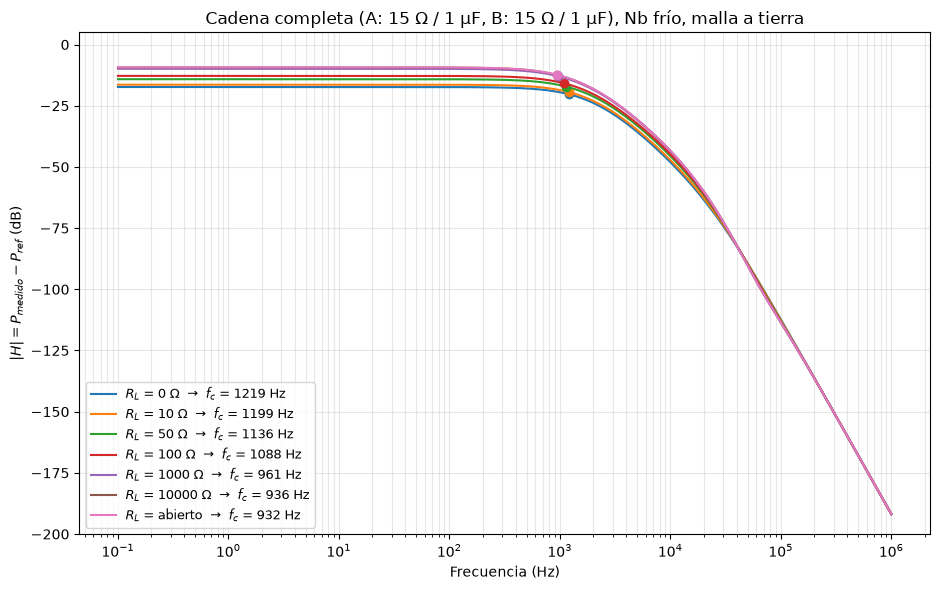

In [11]:
R_L_lista = [0, 10, 50, 100, 1000, 10000, ABIERTO]

fig, ax = plt.subplots(figsize=(9.5, 6))
for R_L in R_L_lista:
    H = lambda fr: H_cadena(fr, R_L)
    fc = frecuencia_corte(H)
    nivel_fc = en_dB(H(F_BAJA)) - CAIDA_3dB
    linea, = ax.semilogx(f, curva_dB(H, f), label=f"$R_L$ = {texto_RL(R_L)}  →  $f_c$ = {fc:.0f} Hz")
    ax.plot(fc, nivel_fc, "o", color=linea.get_color())

ax.set_xlabel("Frecuencia (Hz)")
ax.set_ylabel("$|H| = P_{medido} - P_{ref}$ (dB)")
ax.set_title(f"Cadena completa (A: {AMB_A}, B: {AMB_B}), Nb frío, malla a tierra")
ax.set_ylim(-200, 5)
ax.grid(True, which="both", alpha=0.3)
ax.legend(fontsize=9)
plt.tight_layout()
plt.show()

## 9. $f_c$ vs $R_L$: con crio, sin crio y con Nb caliente
- **Con crio**: la cadena completa con Nb frío.
- **Sin crio**: los filtros criogénicos se reemplazan por cables. Si las dos curvas
  están separadas, el criogénico se nota en la medición.
- **Nb caliente**: con crio, pero con $R_{nb}$ = 1,53 Ω por alambre.

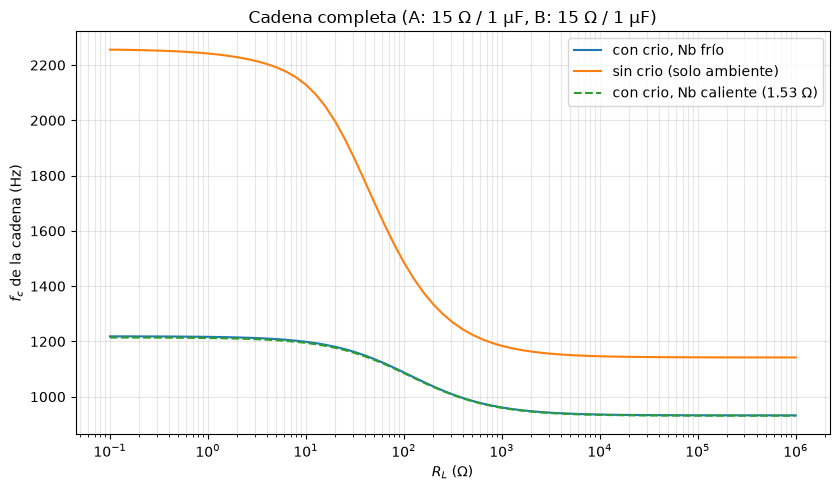

In [12]:
R_L_barrido = np.logspace(-1, 6, 71)     # 0,1 Ω a 1 MΩ
fc_con = np.array([fc_cadena(R) for R in R_L_barrido])
fc_sin = np.array([fc_cadena(R, crio=False) for R in R_L_barrido])
fc_cal = np.array([fc_cadena(R, R_nb=R_nb_caliente) for R in R_L_barrido])

fig, ax = plt.subplots(figsize=(8.5, 5))
ax.semilogx(R_L_barrido, fc_con, label="con crio, Nb frío")
ax.semilogx(R_L_barrido, fc_sin, label="sin crio (solo ambiente)")
ax.semilogx(R_L_barrido, fc_cal, "--", label=f"con crio, Nb caliente ({R_nb_caliente:.2f} Ω)")
ax.set_xlabel("$R_L$ (Ω)")
ax.set_ylabel("$f_c$ de la cadena (Hz)")
ax.set_title(f"Cadena completa (A: {AMB_A}, B: {AMB_B})")
ax.grid(True, which="both", alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

## 10. ¿Cuánto aporta el criogénico? ($R_L$ = 50 Ω)
Se grafica la cadena con crio, sin crio y la **diferencia** en dB (con − sin), que
es la atenuación que agrega el criogénico. La línea horizontal es el piso de ruido
del analizador (`PISO_RUIDO_dB`). Por encima de la frecuencia donde la cadena *con
crio* cruza el piso, la señal se pierde en el ruido y no se puede medir.

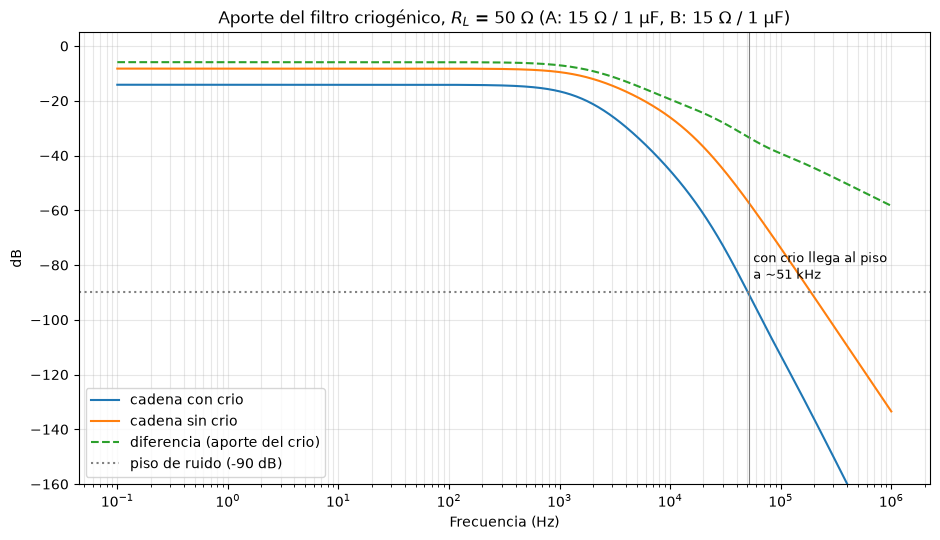

f =     1.0 kHz: con crio   -16.6 dB, sin crio    -9.5 dB, aporte   -7.0 dB
f =    10.0 kHz: con crio   -45.5 dB, sin crio   -26.1 dB, aporte  -19.5 dB
f =    30.2 kHz: con crio   -73.1 dB, sin crio   -45.1 dB, aporte  -28.0 dB
f =   100.0 kHz: con crio  -113.0 dB, sin crio   -73.8 dB, aporte  -39.3 dB


In [13]:
R_L_aporte = 50
con_crio = curva_dB(lambda fr: H_cadena(fr, R_L_aporte), f)
sin_crio = curva_dB(lambda fr: H_cadena(fr, R_L_aporte, crio=False), f)
aporte = con_crio - sin_crio

# Frecuencia donde la cadena con crio cruza el piso de ruido (primer punto debajo)
debajo = np.where(con_crio < PISO_RUIDO_dB)[0]
f_piso = f[debajo[0]] if len(debajo) else None

fig, ax = plt.subplots(figsize=(9.5, 5.5))
ax.semilogx(f, con_crio, label="cadena con crio")
ax.semilogx(f, sin_crio, label="cadena sin crio")
ax.semilogx(f, aporte, "--", label="diferencia (aporte del crio)")
ax.axhline(PISO_RUIDO_dB, color="gray", ls=":", label=f"piso de ruido ({PISO_RUIDO_dB:g} dB)")
if f_piso is not None:
    ax.axvline(f_piso, color="gray", lw=0.8)
    ax.text(f_piso * 1.1, PISO_RUIDO_dB + 5, f"con crio llega al piso\na ~{f_piso/1e3:.0f} kHz", fontsize=9)
ax.set_xlabel("Frecuencia (Hz)")
ax.set_ylabel("dB")
ax.set_title(f"Aporte del filtro criogénico, $R_L$ = {R_L_aporte} Ω (A: {AMB_A}, B: {AMB_B})")
ax.set_ylim(-160, 5)
ax.grid(True, which="both", alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

# Algunos valores puntuales del aporte del crio
for fr in [1e3, 1e4, 3e4, 1e5]:
    i = np.argmin(np.abs(f - fr))
    print(f"f = {f[i]/1e3:7.1f} kHz: con crio {con_crio[i]:7.1f} dB, sin crio {sin_crio[i]:7.1f} dB, aporte {aporte[i]:6.1f} dB")

## 11. Tabla por configuración del ambiente (A y B iguales)
Para $R_L$ = 50 Ω y abierto: $f_c$ con crio, $f_c$ sin crio y nivel a baja frecuencia
(con crio).

In [14]:
filas = []
for conf in CONFIGS_AMB:
    for R_L in [50, ABIERTO]:
        op = dict(amb_A=conf, amb_B=conf)
        fc_c = fc_cadena(R_L, **op)
        fc_s = fc_cadena(R_L, crio=False, **op)
        filas.append({
            "configuración": conf,
            "R_L": texto_RL(R_L),
            "f_c con crio (Hz)": round(fc_c, 1),
            "f_c sin crio (Hz)": round(fc_s, 1),
            "f_c con/sin (%)": round(100 * (fc_c - fc_s) / fc_s, 1),
            "nivel a baja f (dB)": round(nivel_bajo(R_L, **op), 2),
        })
tabla_configs = pd.DataFrame(filas).set_index(["configuración", "R_L"])
tabla_configs

f_c con crio (Hz)  f_c sin crio (Hz)  f_c con/sin (%)  \
configuración  R_L                                                              
150 Ω / 2,2 µF 50 Ω                 154.2              160.8             -4.1   
               abierto              134.2              141.8             -5.4   
150 Ω / 1 µF   50 Ω                 339.5              353.7             -4.0   
               abierto              286.0              312.0             -8.3   
51 Ω / 2,2 µF  50 Ω                 332.6              402.8            -17.4   
               abierto              273.6              304.5            -10.2   
51 Ω / 1 µF    50 Ω                 729.7              886.2            -17.7   
               abierto              584.6              670.0            -12.7   
15 Ω / 2,2 µF  50 Ω                 521.2              774.0            -32.7   
               abierto              434.9              519.1            -16.2   
15 Ω / 1 µF    50 Ω                1136.4             1702.8            -33.3   
               abierto              932.5             1142.1            -18.4   

                        nivel a baja f (dB)  
configuración  R_L                           
150 Ω / 2,2 µF 50 Ω                  -23.94  
               abierto               -18.40  
150 Ω / 1 µF   50 Ω                  -23.94  
               abierto               -18.40  
51 Ω / 2,2 µF  50 Ω                  -17.96  
               abierto               -12.79  
51 Ω / 1 µF    50 Ω                  -17.96  
               abierto               -12.79  
15 Ω / 2,2 µF  50 Ω                  -14.14  
               abierto                -9.31  
15 Ω / 1 µF    50 Ω                  -14.14  
               abierto                -9.31

## 12. Malla a tierra vs. diferencial
Misma cadena, $R_L$ = 50 Ω. En modo malla, la línea − del canal A va a tierra, así que
la señal no es puramente diferencial y parte de la corriente vuelve por los C a
tierra del filtro ambiente.

In [15]:
for modo in ["malla", "diferencial"]:
    print(f"{modo:12s}: f_c = {fc_cadena(50, modo=modo):7.1f} Hz, "
          f"nivel a baja f = {nivel_bajo(50, modo=modo):6.2f} dB")

malla       : f_c =  1136.4 Hz, nivel a baja f = -14.14 dB
diferencial : f_c =  1732.4 Hz, nivel a baja f = -24.38 dB


## 13. Conclusiones
Con la configuración por defecto (15 Ω / 1 µF en A y B, malla a tierra):

1. **El criogénico se nota en la medición.** Con $R_L$ = 50 Ω, la $f_c$ de la cadena
   baja de 1703 Hz (sin crio) a 1136 Hz (con crio), un −33 %. Además, el crio agrega
   atenuación: −7 dB a 1 kHz, −19,5 dB a 10 kHz y −28 dB a 30 kHz.
2. **Hay rango para verlo.** Con un piso de ruido de −90 dB, la cadena con crio
   llega al piso cerca de 51 kHz. Entre ~1 y ~50 kHz se puede comparar con y sin crio.
3. **Conviene la configuración de ambiente con $f_c$ más alta (15 Ω / 1 µF).** Con
   150 Ω / 2,2 µF el ambiente corta tan abajo (~160 Hz) que el crio cambia la $f_c$
   solo un −4 %. Con 15 Ω / 1 µF el cambio es −33 % ($R_L$ = 50 Ω).
4. **El Nb caliente casi no influye** (1136 → 1133 Hz con 50 Ω). En el modelo, medir el
   lazo a temperatura ambiente da casi lo mismo que en frío. *Ojo:* el modelo no
   incluye que las R y los C del criogénico también cambian con la temperatura.
5. **$R_L$:** con crio, la $f_c$ va de 1219 Hz (corto) a 932 Hz (abierto). Sin crio la
   dependencia con $R_L$ es mucho más fuerte (2250 → 1142 Hz), así que la $R_L$ hay que
   conocerla bien si se quiere separar el crio comparando con y sin.
6. **Nivel a baja frecuencia:** incluso a 0,1 Hz la cadena con crio está 6 dB por
   debajo de sin crio ($R_L$ = 50 Ω: −14,1 vs −8,1 dB). Son las 6 × 22 Ω en serie del
   crio, que forman un divisor con $R_L$ y con los 50 Ω. Eso hay que tenerlo en cuenta
   antes de atribuir una diferencia de nivel a otra cosa.
7. **Malla vs. diferencial:** cambian bastante ($f_c$ 1136 vs 1732 Hz con 50 Ω). Hay
   que comparar la medición con el modo en que realmente se conecta (malla a tierra).